In [2]:
from uci_gas_sensor_dataset import UCIGasSensorDataset

dataset = UCIGasSensorDataset()
dataset.load()
data = dataset.df

In [4]:
import pandas as pd

X = data[dataset.feature_columns].to_numpy()
y = data["gas"].to_numpy()
batch = data["batch"].to_numpy()

print(pd.crosstab(data["batch"], data["gas_name"])) 

gas_name  acetaldehyde  acetone  ammonia  ethanol  ethylene  toluene
batch                                                               
1                   30       70       83       90        98       74
2                  109      532      100      164       334        5
3                  240      275      216      365       490        0
4                   30       12       12       64        43        0
5                   46       63       20       28        40        0
6                   29      606      110      514       574      467
7                  744      630      360      649       662      568
8                   33      143       40       30        30       18
9                   75       78      100       61        55      101
10                 600      600      600      600       600      600


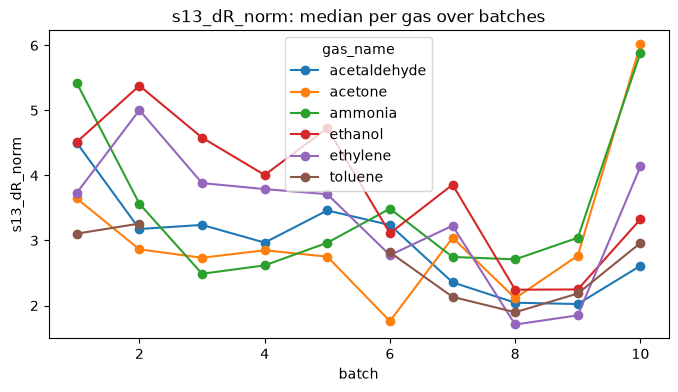

In [5]:
import matplotlib.pyplot as plt
feat = "s13_dR_norm"
med = data.groupby(["batch", "gas_name"])[feat].median().unstack()
med.plot(marker="o", figsize=(8, 4), title=f"{feat}: median per gas over batches")
plt.ylabel(feat); plt.show()

<Axes: xlabel='x', ylabel='y'>

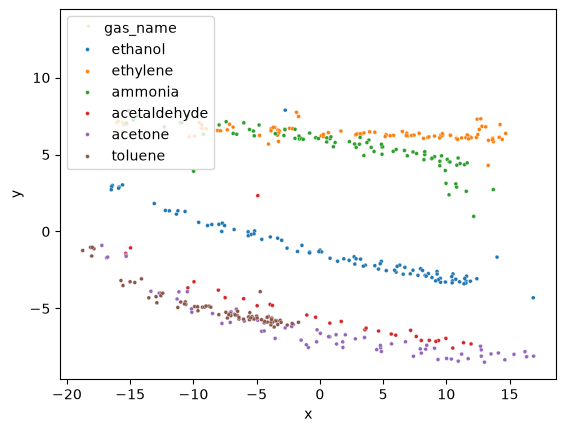

In [6]:
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import seaborn as sns

slog = lambda a: np.sign(a) * np.log1p(np.abs(a))

def pca_batch(b):
    d = data[data["batch"] == b]
    Z = StandardScaler().fit_transform(slog(d[dataset.feature_columns].to_numpy()))
    xy = PCA(n_components=2).fit_transform(Z)
    return d.assign(x=xy[:, 0], y=xy[:, 1])[["x", "y", "gas_name", "batch"]]

pca_df = pca_batch(1)
sns.scatterplot(data=pca_df, x="x", y="y", hue="gas_name", s=8)

<Axes: xlabel='x', ylabel='y'>

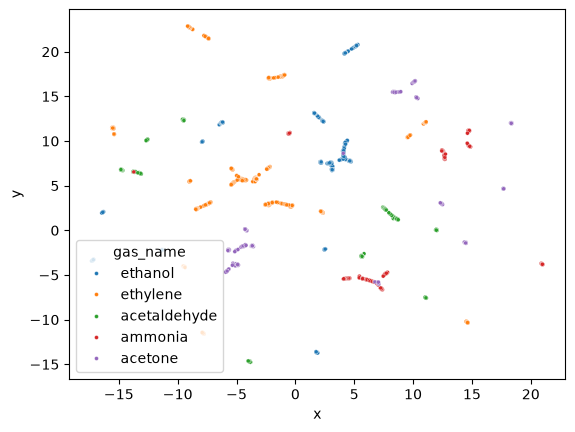

In [7]:
import umap

def umap_batch(b):
    d = data[data["batch"] == b]
    Z = StandardScaler().fit_transform(slog(d[dataset.feature_columns].to_numpy()))
    xy = umap.UMAP().fit_transform(Z)
    return d.assign(x=xy[:, 0], y=xy[:, 1])[["x", "y", "gas_name", "batch"]]

umap_df = umap_batch(3)
sns.scatterplot(data=umap_df, x="x", y="y", hue="gas_name", s=8)